In [59]:
import numpy as np
from sklearn.datasets import make_blobs
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

In [93]:
#This is a bloc to initialize the matrix and vector we gonna use in the perceptron's demonstration
X,y = make_blobs(n_samples = 100, n_features = 2,centers = 2, random_state = 0)
print(y.shape)
y = y.reshape(y.shape[0], 1)
print(y)
print(X)

(100,)
[[1]
 [1]
 [0]
 [0]
 [1]
 [0]
 [0]
 [1]
 [0]
 [1]
 [0]
 [1]
 [0]
 [0]
 [1]
 [1]
 [1]
 [0]
 [1]
 [1]
 [0]
 [0]
 [1]
 [0]
 [1]
 [0]
 [1]
 [0]
 [0]
 [1]
 [1]
 [0]
 [1]
 [1]
 [1]
 [0]
 [1]
 [1]
 [0]
 [1]
 [0]
 [0]
 [0]
 [0]
 [1]
 [1]
 [1]
 [1]
 [0]
 [0]
 [1]
 [1]
 [0]
 [0]
 [0]
 [0]
 [0]
 [1]
 [1]
 [1]
 [1]
 [0]
 [0]
 [1]
 [0]
 [1]
 [0]
 [0]
 [1]
 [0]
 [0]
 [1]
 [1]
 [0]
 [0]
 [0]
 [1]
 [1]
 [0]
 [0]
 [1]
 [0]
 [0]
 [0]
 [0]
 [0]
 [1]
 [0]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [0]
 [0]
 [1]
 [1]
 [0]
 [1]]
[[ 4.21850347  2.23419161]
 [ 0.90779887  0.45984362]
 [-0.27652528  5.08127768]
 [ 0.08848433  2.32299086]
 [ 3.24329731  1.21460627]
 [ 1.44193252  2.76754364]
 [ 1.0220286   4.11660348]
 [ 3.97820955  2.37817845]
 [ 0.58894326  4.00148458]
 [ 1.25185786  0.20811388]
 [ 0.62835793  4.4601363 ]
 [ 1.68608568  0.65828448]
 [ 1.18454506  5.28042636]
 [ 0.06897171  4.35573272]
 [ 1.78726415  1.70012006]
 [ 4.4384123   1.84214315]
 [ 3.18190344 -0.18226785]
 [ 0.30380963  3.94423417]
 [ 0.7

In [20]:
def initialization(X):
    W = np.random.randn(X.shape[1], 1)
    b = np.random.randn(1)
    return (W,b)

In [21]:
W,b = initialization(X)
W.shape

(2, 1)

In [33]:
# Part use to define the model (Perceptron) we gonna use
def model(X,W,b):
    Z = X @ W + b
    A = 1/(1+np.exp(-Z))
    return A

In [30]:
# Part use to define the function that measure the Loss
def log_loss(A,y):
    m = len(y)
    return (-1/m) * np.sum(y * np.log(A) + (1 - y) * np.log(1 - A))

In [31]:
# Part use to define the function that calculate the gradient descent
def gradients(A,X,y):
    dW = (1/len(y)) * ((X.T) @ (A - y))
    db = (1/len(y)) * (np.sum(A - y))
    return (dW,db)

In [98]:
# Part for the function that predict
def predict(X,W,b):
    A = model(X,W,b)
    return A >= 0.5

In [37]:
# Part use to optimise the Weights and Biais 
def optimisation(dW, db, W, b, learning_rate):
    W = W - learning_rate * dW
    b = b - learning_rate * db
    return (W,b)

In [99]:
# This is the main part of the machine learning function , that gather all those function above and allow to train our Perceptron
def artificial_neuron(X, y, learning_rate = 0.1, nb_iteration = 100):
    W,b = initialization(X)
    loss_value = []
    y_predict = []
    for i in range (nb_iteration):
        A = model(X,W,b)
        Loss = log_loss(A,y)
        dW,db = gradients(A,X,y)
        W,b = optimisation(dW, db, W, b, learning_rate)
        loss_value.append(Loss)
    # Prediction part, but WARNING!!!, this prediction is on the train set
    y_predict = predict(X,b,W)
    print("This is the score of accuracy :")
    print(accuracy_score(y, y_predict))
    # In order to see the evolution the upgrade and optimization of the Perceptron by his Loss perfomance
    plt.plot(loss_value)
    plt.show()

This is the score of accuracy :
0.91


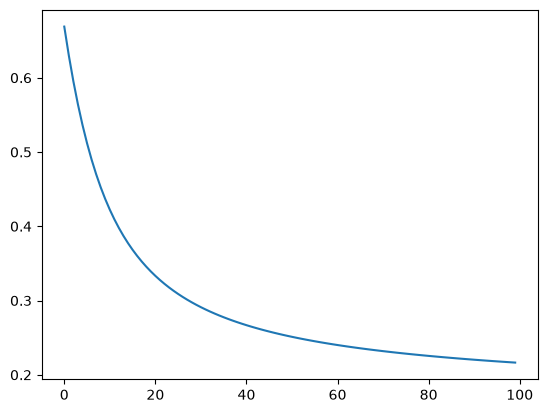

In [97]:
artificial_neuron(X,y)